# Copy number and malignancy from scRNA with inferCNV

We load a pregrown tumor, measure its dissociated cells by single-cell RNA sequencing (scRNA-seq) over the human genes, and call copy number and malignancy with inferCNV ([Tickle et al. 2019](https://github.com/broadinstitute/inferCNV)) through its Python implementation, [infercnvpy](https://github.com/icbi-lab/infercnvpy).
We then score the calls against the answer key, in which every cell has its malignancy and its copy number on every chromosome arm, and we split the scores by the niche each cell came from.

We use inferCNV rather than Numbat, which also reads allele counts at germline SNPs.
Numbat needs the 1000 Genomes list of common SNPs, a 92 MB download that [`fetch_snps`](https://pedrofale.github.io/iscc/reference/fetch_snps/) prepares, and in a separate run on a data set of 3,000 cells like this one it had not finished its first iteration after 15 minutes on four laptop cores, which is too long for a tutorial.
The tool runs in its own conda environment, `iscc-infercnv`, from a short script that the notebook writes, so its code stays visible and standard.

In [1]:
import os
import tempfile

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from matplotlib.colors import TwoSlopeNorm
from sklearn.metrics import roc_auc_score

import iscc.pregrown
from iscc.data import scRNA
from iscc.data.human import HumanGenomeLayer, write_scrna
from iscc.sample import Resection

INFERCNV_PYTHON = os.path.expanduser("~/miniconda3/envs/iscc-infercnv/bin/python")
os.chdir(tempfile.mkdtemp())        # the data and the tool's outputs go to a scratch directory

## The pregrown ductal tumor

We load the pregrown ductal tumor ([`iscc.pregrown.ductal`](https://pedrofale.github.io/iscc/reference/#pregrown-tumors)), the tumor of the paper's regime with 200,284 cancer cells on a field of 1 cm, which have invaded the stroma from several glands while other glands still hold tumors in situ.
Its genome has one segment per chromosome arm ([`arm_genome`](https://pedrofale.github.io/iscc/reference/arm_genome/)), so that a copy-number event changes one chromosome arm, as in a real genome.
The epithelium is its cell of origin, so that cancer cells share the expression baseline of normal epithelial cells and differ from them only by what evolution did to them (copy number, mutations and programs).

200,284 cancer cells after 299 generations


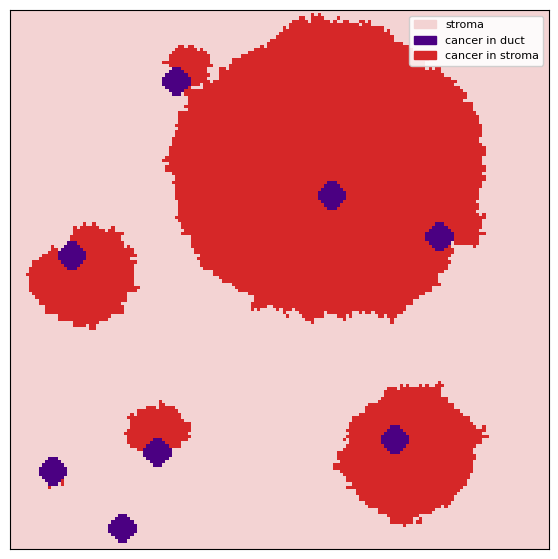

In [2]:
tumor = iscc.pregrown.ductal()
print(f"{tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")
tumor.plot_tissue();

## scRNA-seq of the dissociated tumor

We dissociate the resected tumor into about 3,000 cells and lift the growth genome onto the human genome with [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/), whose expression gives each cell type the baseline of the Human Breast Cell Atlas.
We measure the cells with the 10x Genomics preset of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/).
[`write_scrna`](https://pedrofale.github.io/iscc/reference/write_scrna/) writes the counts as Cell Ranger output, with the gene positions that inferCNV needs, and keeps the answer key in a separate `truth` folder that no tool reads.

In [3]:
cells = Resection(tumor).dissociate(max_cells=3000)
layer = HumanGenomeLayer(tumor)
rna = scRNA(protocol="10x", n_cells=len(cells["cell_exp"]), seed=1).run(
    cells, gene_lift=layer.expression(tumor))
write_scrna("scrna", rna, layer, cells, tumor=tumor)
print(f"{rna.obs.shape[0]:,} cells and {len(layer.genes):,} genes, with a median of "
      f"{rna.obs['n_counts'].median():,.0f} UMIs and {rna.obs['n_genes'].median():,.0f} detected genes per cell")

3,112 cells and 35,061 genes, with a median of 3,542 UMIs and 1,285 detected genes per cell


In the answer key, each barcode comes with its cell and genotype.
We add the cell type and the niche of each cell, that is, whether it came from inside a duct or from the stroma, and we set the doublets aside, since their true state is a mixture.

In [4]:
truth = pd.read_csv("scrna/truth/cells.tsv", sep="\t", index_col="barcode", dtype={"genotype": str})
truth["cell_type"] = np.where(truth["is_tumour"], "cancer", truth["genotype"])
in_duct = cells["cell_gland"]["gland_id"].reindex(truth["cell"]).to_numpy() >= 0
truth["niche"] = np.where(in_duct, "duct", "stroma")
truth = truth[~truth["is_doublet"]]
pd.crosstab(truth["cell_type"], truth["niche"])

niche,duct,stroma
cell_type,,
cancer,127,1114
epithelial,70,0
stromal,0,1645


## inferCNV with the microenvironment as the reference

inferCNV compares the expression of each cell, averaged along the genome, with a reference of normal cells.
As a user would, we take the cells of the microenvironment as the reference, since they can be annotated from marker genes.
Here the microenvironment is the stroma, since the tumor holds no immune cells.
Normal epithelial cells can not be told apart from cancer cells by their markers, so they stay out of the reference and are scored with the cancer cells.

In [5]:
reference = truth.index[truth["cell_type"] == "stromal"]
pd.Series(reference).to_csv("reference_barcodes.txt", index=False, header=False)
print(f"{len(reference):,} reference cells")

1,645 reference cells


The script below runs infercnvpy's standard workflow, as in its tutorial.
It normalizes and log-transforms the counts, runs `infercnv` against the reference with the default window of 100 genes, clusters the cells on their copy-number profiles, scores each cluster and draws the chromosome heatmap.
The gene positions come from the BED file that `write_scrna` writes.

In [6]:
%%writefile run_infercnv.py
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import infercnvpy as cnv


def main(data):
    adata = sc.read_10x_h5(f"{data}/outs/filtered_feature_bc_matrix.h5")
    adata.var_names = adata.var["gene_ids"]                     # Ensembl IDs, which are unique
    genes = pd.read_csv(f"{data}/clonalscope/genes.bed", sep="\t", index_col="geneID")
    adata.var["chromosome"] = genes.loc[adata.var_names, "chr"].to_numpy()
    adata.var["start"] = genes.loc[adata.var_names, "start"].to_numpy()
    adata.var["end"] = genes.loc[adata.var_names, "end"].to_numpy()
    reference = pd.read_csv("reference_barcodes.txt", header=None)[0]
    adata.obs["annotation"] = np.where(adata.obs_names.isin(reference), "microenvironment", "unknown")

    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    cnv.tl.infercnv(adata, reference_key="annotation", reference_cat="microenvironment")
    cnv.tl.pca(adata)
    cnv.pp.neighbors(adata)
    cnv.tl.leiden(adata)
    cnv.tl.cnv_score(adata)

    cnv.pl.chromosome_heatmap(adata, groupby="cnv_leiden", show=False)
    plt.savefig("infercnv_heatmap.png", dpi=100, bbox_inches="tight")
    adata.write_h5ad("infercnv.h5ad")
    print(f"infercnvpy {cnv.__version__}: {adata.n_obs} cells in {adata.obs['cnv_leiden'].nunique()} clusters")


if __name__ == "__main__":      # infercnvpy starts worker processes, which import this script again
    main(sys.argv[1])

Writing run_infercnv.py


In [7]:
!MPLBACKEND=Agg TQDM_DISABLE=1 {INFERCNV_PYTHON} -W ignore run_infercnv.py scrna 2> infercnv.log

infercnvpy 0.6.1: 3112 cells in 7 clusters


infercnvpy's chromosome heatmap shows one row per cell, grouped by the copy-number clusters it found, with gains in red and losses in blue relative to the reference.

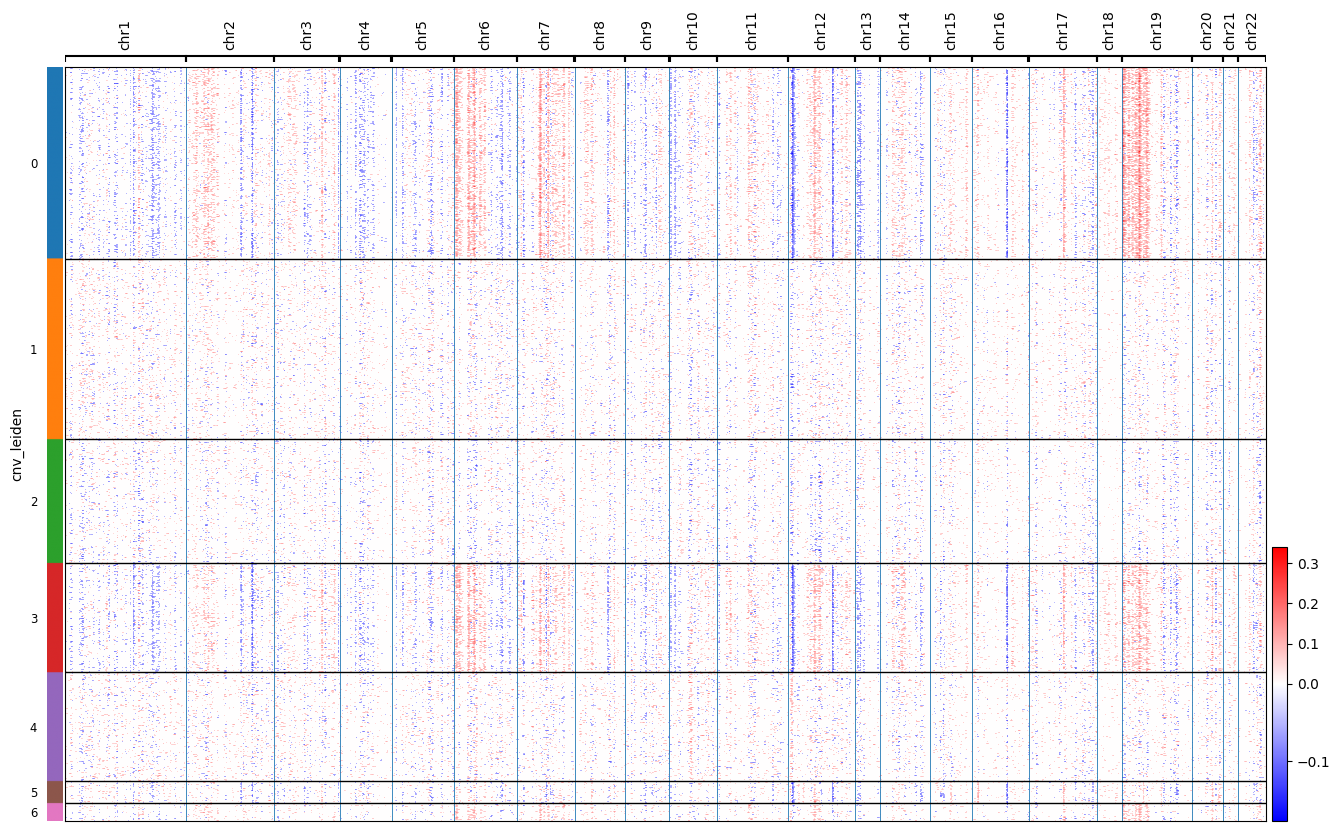

In [8]:
Image("infercnv_heatmap.png")

## inferCNV separates cancer cells from normal epithelial cells in both niches

infercnvpy scores each cluster by the mean absolute copy-number signal of its cells, and a user calls the clusters with a high score malignant.
We read this score as a malignancy score on the epithelial cells, cancer cells against normal epithelial cells, and compute its area under the ROC curve (AUC), which is 1 for a perfect separation and 0.5 for none.
We compute it over all epithelial cells and, for the cancer cells of each niche, against all normal epithelial cells.

In [9]:
result = ad.read_h5ad("infercnv.h5ad")
score = result.obs["cnv_score"].reindex(truth.index)
cancer = truth["cell_type"] == "cancer"
normal_epithelial = truth["cell_type"] == "epithelial"
groups = {"all": cancer, "in a duct": cancer & (truth["niche"] == "duct"),
          "in the stroma": cancer & (truth["niche"] == "stroma")}
for name, tumor_cells in groups.items():
    scored = tumor_cells | normal_epithelial
    auc = roc_auc_score(tumor_cells[scored], score[scored])
    print(f"cancer cells {name:>14}: {tumor_cells.sum():4d} cells, AUC {auc:.2f}")

cancer cells            all: 1241 cells, AUC 0.99
cancer cells      in a duct:  127 cells, AUC 0.91


cancer cells  in the stroma: 1114 cells, AUC 1.00


## inferCNV reads copy number relative to ploidy

inferCNV reports a smoothed log ratio in windows of 100 genes, moved along each chromosome by 10 genes.
We average the windows of each chromosome arm, assigning a window to the chromosome arm of its middle gene, and compare the result with the true copy number of the chromosome arm in each cancer cell.

In [10]:
genes = layer.genes.assign(chromosome=layer.genes["chrom"].str[3:].astype(int))
genes = genes.sort_values(["chromosome", "start"])            # infercnvpy's order of the genes
window_arm = np.concatenate([g["arm"].to_numpy()[np.arange(0, len(g) - 99, 10) + 50]
                             for _, g in genes.groupby("chromosome")])
arms = pd.unique(genes["arm"])
inferred = pd.DataFrame(result.obsm["X_cnv"].toarray(), index=result.obs_names)
inferred = inferred.T.groupby(window_arm).mean().T[arms].reindex(truth.index)

segments = pd.read_csv("scrna/truth/cn_segments.tsv", sep="\t", dtype={"genotype": str})
true_cn = segments.pivot(index="genotype", columns="arm", values="cn").loc[truth["genotype"], arms]
true_cn.index = truth.index

The heatmaps show the true copy number of each cancer cell on each chromosome arm (A) and inferCNV's value for it (B), with the cells in the same order.

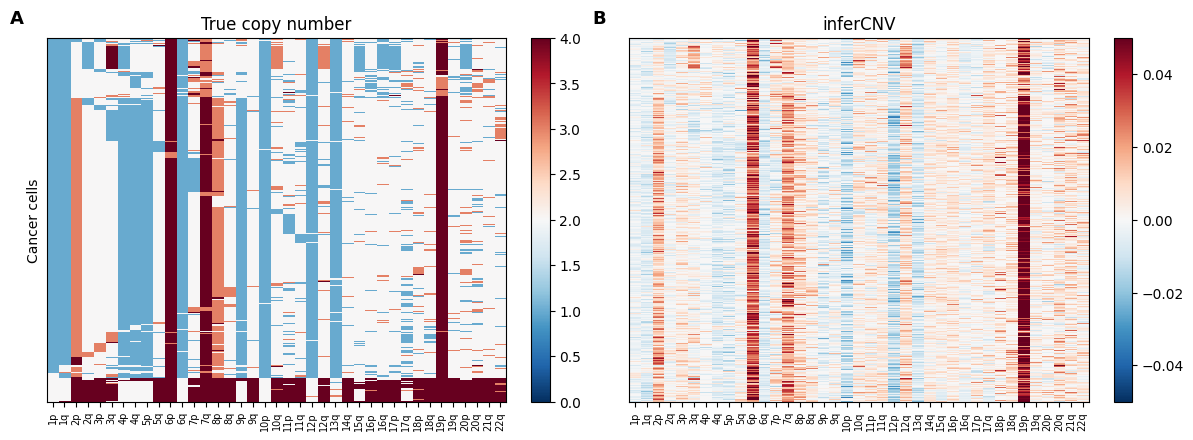

In [11]:
order = true_cn[cancer].sort_values(list(arms)).index
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
panels = [(true_cn, "True copy number", "RdBu_r", TwoSlopeNorm(vcenter=2, vmin=0, vmax=4)),
          (inferred, "inferCNV", "RdBu_r", TwoSlopeNorm(vcenter=0, vmin=-0.05, vmax=0.05))]
for ax, (values, title, cmap, norm), letter in zip(axes, panels, "AB"):
    im = ax.imshow(values.loc[order].to_numpy(), aspect="auto", interpolation="none", cmap=cmap, norm=norm)
    ax.set_xticks(range(len(arms)), arms, rotation=90, fontsize=7)
    ax.set_title(title)
    ax.text(-0.08, 1.04, letter, transform=ax.transAxes, fontweight="bold", fontsize=13)
    fig.colorbar(im, ax=ax, fraction=0.04)
axes[0].set_ylabel("Cancer cells")
axes[0].set_yticks([])
plt.tight_layout()

We summarize the agreement by the Pearson correlation between inferCNV's values and the true copy number over the cancer cells and chromosome arms, in all cancer cells and in each niche.
inferCNV reads the expression of a cell relative to the library size of the cell, so in principle it sees copy number only relative to the ploidy of the cell.
We therefore also compare its values with the true copy number divided by the mean copy number over the chromosome arms of the same cell, and we report the share of cancer cells with a whole-genome doubling and the number of chromosome arms whose copy number differs from two.

In [12]:
relative_cn = true_cn.div(true_cn.mean(axis=1), axis=0)          # relative to the ploidy of each cell
doubled = cells["cell_wgd"]["is_wgd"].reindex(truth["cell"]).to_numpy()
changed = (true_cn != 2).sum(axis=1)                               # chromosome arms not at two copies
for name, tumor_cells in groups.items():
    values = inferred[tumor_cells].to_numpy().ravel()
    r_total = np.corrcoef(values, true_cn[tumor_cells].to_numpy().ravel())[0, 1]
    r_relative = np.corrcoef(values, relative_cn[tumor_cells].to_numpy().ravel())[0, 1]
    print(f"cancer cells {name:>14}: {changed[tumor_cells].median():2.0f} chromosome arms changed (median), "
          f"{doubled[tumor_cells.to_numpy()].mean():3.0%} doubled, Pearson r {r_total:.2f} with the copy number "
          f"and {r_relative:.2f} with the copy number relative to ploidy")

cancer cells            all: 17 chromosome arms changed (median),  7% doubled, Pearson r 0.71 with the copy number and 0.81 with the copy number relative to ploidy
cancer cells      in a duct: 16 chromosome arms changed (median),  5% doubled, Pearson r 0.65 with the copy number and 0.73 with the copy number relative to ploidy
cancer cells  in the stroma: 17 chromosome arms changed (median),  7% doubled, Pearson r 0.72 with the copy number and 0.82 with the copy number relative to ploidy


inferCNV separated cancer cells from normal epithelial cells almost perfectly, with an AUC of 0.99 over all epithelial cells.
The separation was complete for the cancer cells that had invaded the stroma (1.00) and weaker for the 127 cancer cells in the ducts (0.91), although these carry about as many changed chromosome arms (a median of 16, against 17 in the stroma).
inferCNV's values per chromosome arm agreed with the true copy number with a Pearson r of 0.71.
In the heatmaps, the gains of 2p, 6p, 7q and 19p (A) stand out in inferCNV's values (B), the losses are fainter, and the cancer cells with a whole-genome doubling, at the bottom of A, are not distinct in B.
A doubling multiplies every copy number by two and leaves the relative expression of the genes unchanged, so, as expected for a method that reads expression relative to the library size, inferCNV can not see it.
Against the copy number relative to ploidy, the correlation rose to 0.81.
Of the cancer cells, 7% were doubled (5% in the ducts and 7% in the stroma), and both correlations were lower in the ducts (0.65 and 0.73) than in the stroma (0.72 and 0.82).

## Making the benchmark harder or easier

Each choice above is a setting a user can move, and [Shape the data](03_shape_the_data.ipynb) shows the assay settings in more detail.
The depth of the scRNA data (`n_reads` of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/)) sets the signal in each cell, and a dropout curve (`dropout_mid`, off in the 10x preset) makes the cells sparser.
The number of dissociated cells sets how many cancer cells there are to call.
The other [pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors) change the copy-number landscape.
In `iscc.pregrown.cin` every cancer cell has a doubled genome and the clones differ mostly in copy number, and in `iscc.pregrown.sweeps` a third of the cancer cells are doubled.
[Shape the tumor](02_shape_the_tumor.ipynb) shows how to grow a tumor with other rates of copy-number events and genome doubling.
A reference that holds normal epithelial cells makes the task easier than any annotation from markers can, and a reference of fewer microenvironment cells makes it harder.